

In this project, I am using the **Air Quality Data in India (2015–2020)** dataset (`city_day.csv`) to predict the Air Quality Index (AQI) based on 7 major pollutants: `PM2.5`, `PM10`, `NO2`, `NH3`, `CO`, `SO2`, and `O3`.

## 1. Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("city_day.csv")

print("Original Dataset Shape:", df.shape)
df.head()

Original Dataset Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Cleaning the Data

In [2]:
features = ['PM2.5', 'PM10', 'NO2', 'NH3', 'CO', 'SO2', 'O3']
target = 'AQI'

print("Missing values BEFORE cleaning:")
print(df[features + [target]].isnull().sum())

df_clean = df.dropna(subset=[target]).copy()

for col in features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("\nMissing values AFTER cleaning:")
print(df_clean[features + [target]].isnull().sum())
print("\nCleaned Dataset Shape:", df_clean.shape)

Missing values BEFORE cleaning:
PM2.5     4598
PM10     11140
NO2       3585
NH3      10328
CO        2059
SO2       3854
O3        4022
AQI       4681
dtype: int64

Missing values AFTER cleaning:
PM2.5    0
PM10     0
NO2      0
NH3      0
CO       0
SO2      0
O3       0
AQI      0
dtype: int64

Cleaned Dataset Shape: (24850, 16)


## 3. Exploratory Data Analysis (EDA)



C:\Users\KORUPURI RAMU\AppData\Local\Temp\ipykernel_13460\1527225729.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cities.values, y=top_cities.index, palette='Reds_r')


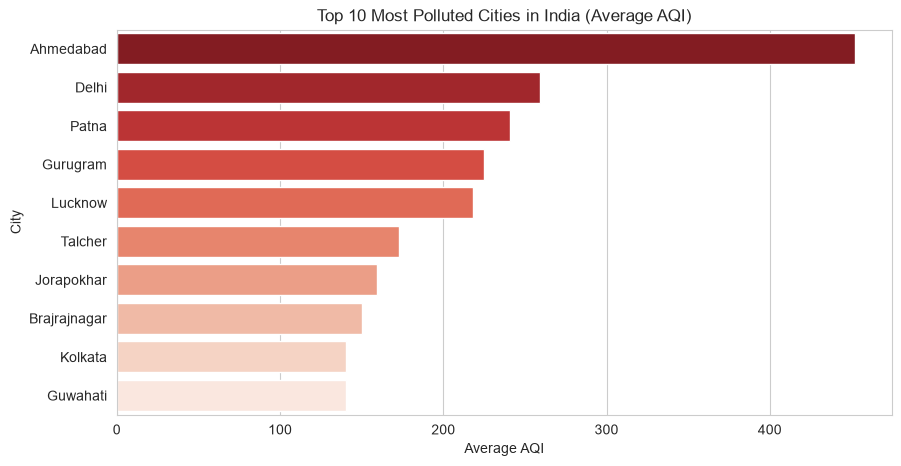

In [3]:
sns.set_style("whitegrid")

top_cities = df_clean.groupby('City')['AQI'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_cities.values, y=top_cities.index, palette='Reds_r')
plt.title("Top 10 Most Polluted Cities in India (Average AQI)")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.show()

### AQI Category Breakdown
Here, I am plotting how many days fell into each Indian CPCB air quality bucket (from Good to Severe) to see what the overall distribution looks like.

C:\Users\KORUPURI RAMU\AppData\Local\Temp\ipykernel_13460\629655499.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='AQI_Bucket', order=order, palette='YlOrRd')


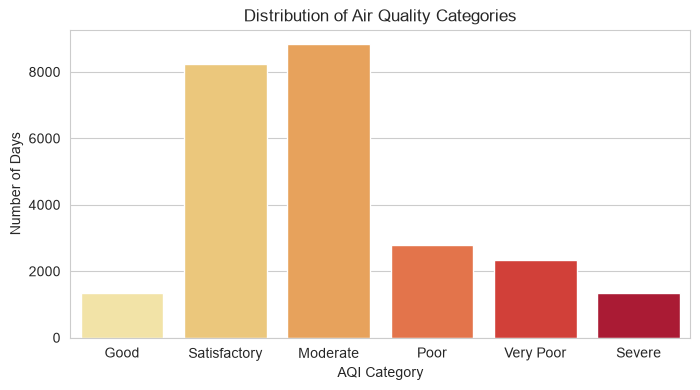

In [4]:

order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']

plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='AQI_Bucket', order=order, palette='YlOrRd')
plt.title("Distribution of Air Quality Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Days")
plt.show()

### Pollutant Correlations
This heatmap helps us see which pollutants have the strongest relationship with the final AQI score.

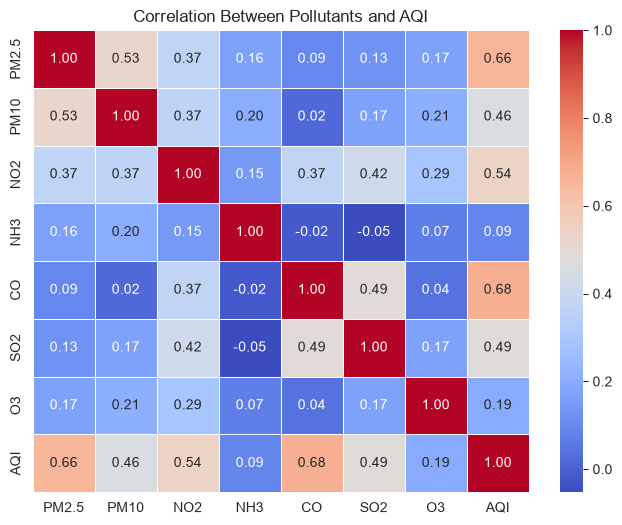

In [5]:

plt.figure(figsize=(8, 6))
corr_matrix = df_clean[features + [target]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Between Pollutants and AQI")
plt.show()

## 4. Training and Comparing Models
Next, I split the cleaned data into 80% for training and 20% for testing. Since AQI is a continuous number, this is a regression problem, so I am comparing three models:
* Linear Regression
* Decision Tree Regressor
* Random Forest Regressor

Instead of accuracy, I'm evaluating them using **R² Score** (higher is better), along with **MAE** and **RMSE** (lower is better).

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })
    
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print(" Model Performance Comparison")
display(results_df)

 Model Performance Comparison


,Model,R2 Score,MAE,RMSE
2,Random Forest,0.9051,21.58,41.68
0,Linear Regression,0.8067,31.14,59.49
1,Decision Tree,0.7815,30.55,63.25


## 5. Actual vs. Predicted AQI
To visually check how well the winning model performs, I plotted its predicted AQI values against the actual values from the test set. The closer the dots are to the red dashed line, the better the predictions.

Best Model: Random Forest


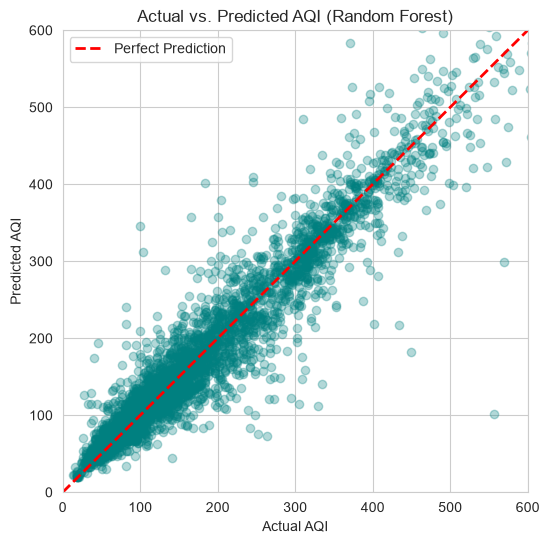

In [7]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print(f"Best Model: {best_model_name}")

y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, color='teal')
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=2, label="Perfect Prediction")
plt.xlim(0, 600)
plt.ylim(0, 600)
plt.title(f"Actual vs. Predicted AQI ({best_model_name})")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.legend()
plt.show()

## 6. Saving the Best Model
Finally, I save the best-performing model as `models/aqi_model.pkl` using `joblib` so it can be reused later to make new AQI predictions without retraining from scratch.

In [8]:
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/aqi_model.pkl")
joblib.dump(best_model, "models/aqi_model.pkl", compress=3)

print(f"Saved {best_model_name} successfully to models/aqi_model.pkl!")

Saved Random Forest successfully to models/aqi_model.pkl!
